## 1. Importing libraries

In [1]:
import os
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    recall_score,
    roc_curve,
    classification_report
)

from IPython.display import display

## 2. Randomization using seed

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


## 3. Load and prepare dataset

In [3]:
TRAIN_PATH = "/content/heart_train_processed.csv"
VAL_PATH = "/content/heart_val_processed.csv"
TEST_PATH = "/content/heart_test_processed.csv"

TARGET_COLUMN = "target"

# Load datasets
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training dataset shape:", train_df.shape)
print("Validation dataset shape:", val_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (587, 17)
Validation dataset shape: (147, 17)
Testing dataset shape: (184, 17)


## 4. Inspect datasets

In [4]:
print("Training Dataset:")
display(train_df.head())

print("\nValidation Dataset:")
display(val_df.head())

print("\nTesting Dataset:")
display(test_df.head())

print("\nTraining Dataset Information:")
train_df.info()

print("\nMissing Values:")
print("Train:", train_df.isnull().sum().sum())
print("Validation:", val_df.isnull().sum().sum())
print("Test:", test_df.isnull().sum().sum())

Training Dataset:


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,Chol_missing,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,HeartDisease
0,0.439478,1,-1.386657,-0.839102,0,-1.031459,0,-0.911046,0,0,0,0,1,0,1,0,1
1,-1.308144,0,-1.241787,0.560352,0,1.408013,1,-0.911046,0,0,1,0,0,0,0,1,0
2,0.222642,1,-0.083689,-0.725996,1,-1.472717,0,0.741291,0,0,0,0,1,0,1,0,1
3,1.564185,0,-0.696869,-0.549930,0,-0.844282,0,0.741291,0,0,1,0,0,0,1,0,0
4,-0.202447,1,1.416269,1.571399,0,-1.617169,1,1.401569,0,0,0,0,1,0,1,0,1



Validation Dataset:


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,Chol_missing,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,HeartDisease
0,0.008645,1,-0.696869,-1.496222,0,0.000559,0,1.095322,0,0,0,1,1,0,0,1,0
1,0.008645,0,0.963651,-0.153798,0,-0.271857,0,-0.911046,0,1,0,0,1,0,0,1,0
2,-0.410563,1,0.671116,1.829607,0,-0.655250,1,0.319757,0,0,0,0,0,0,0,1,1
3,0.769921,1,1.416269,-0.014952,1,0.315773,0,0.319757,1,0,0,0,0,1,1,0,1
4,2.032002,1,-0.696869,-0.485388,0,-1.326921,1,0.319757,0,0,1,0,1,0,1,0,1



Testing Dataset:


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,Chol_missing,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,HeartDisease
0,1.106417,1,0.143269,0.647705,0,-1.326921,1,2.135239,0,0,0,0,1,0,0,0,1
1,0.439478,1,-1.100520,1.377270,0,0.118288,0,2.298263,0,0,0,0,0,1,0,0,1
2,-0.716995,0,0.466366,0.363115,0,-0.077603,0,0.319757,0,1,0,0,1,0,0,1,0
3,1.106417,1,0.518320,0.120399,1,-0.806622,1,0.741291,0,0,0,0,0,1,1,0,1
4,-0.716995,1,-1.386657,-0.014952,1,-0.655250,1,-0.911046,1,0,1,0,1,0,1,0,1



Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 587 entries, 0 to 586
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                587 non-null    float64
 1   Sex                587 non-null    int64  
 2   RestingBP          587 non-null    float64
 3   Cholesterol        587 non-null    float64
 4   FastingBS          587 non-null    int64  
 5   MaxHR              587 non-null    float64
 6   ExerciseAngina     587 non-null    int64  
 7   Oldpeak            587 non-null    float64
 8   Chol_missing       587 non-null    int64  
 9   ChestPainType_ATA  587 non-null    int64  
 10  ChestPainType_NAP  587 non-null    int64  
 11  ChestPainType_TA   587 non-null    int64  
 12  RestingECG_Normal  587 non-null    int64  
 13  RestingECG_ST      587 non-null    int64  
 14  ST_Slope_Flat      587 non-null    int64  
 15  ST_Slope_Up        587 non-null    int64  


## 5. Seperate features and target

In [5]:
# Separate training features and target
X_train = train_df.drop(columns=["HeartDisease"])
y_train = train_df["HeartDisease"]

# Separate validation features and target
X_val = val_df.drop(columns=["HeartDisease"])
y_val = val_df["HeartDisease"]

# Separate testing features and target
X_test = test_df.drop(columns=["HeartDisease"])
y_test = test_df["HeartDisease"]

# Ensure feature columns have identical order
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

print("Number of input features:", X_train.shape[1])

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

Number of input features: 16
Training features: (587, 16)
Validation features: (147, 16)
Testing features: (184, 16)


## 6. Standardizing input features

In [6]:
scaler = StandardScaler()

# Fit on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Standardization completed!")

print("Training mean:", np.mean(X_train_scaled))
print("Training standard deviation:", np.std(X_train_scaled))

Standardization completed!
Training mean: 9.36218734564655e-18
Training standard deviation: 1.0


## 7. Converting datasets into PyTorch tensors

In [7]:
# Convert features
X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

# Convert targets
y_train_tensor = torch.tensor(
    np.asarray(y_train).reshape(-1, 1), dtype=torch.float32
)

y_val_tensor = torch.tensor(
    np.asarray(y_val).reshape(-1, 1), dtype=torch.float32
)

y_test_tensor = torch.tensor(
    np.asarray(y_test).reshape(-1, 1), dtype=torch.float32
)

print("Tensor conversion completed!")

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)

print("X_val:", X_val_tensor.shape)
print("y_val:", y_val_tensor.shape)

print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

Tensor conversion completed!
X_train: torch.Size([587, 16])
y_train: torch.Size([587, 1])
X_val: torch.Size([147, 16])
y_val: torch.Size([147, 1])
X_test: torch.Size([184, 16])
y_test: torch.Size([184, 1])


## 8. Create DataLoaders



In [8]:
BATCH_SIZE = 32

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


## 9. Define neural network architecture

In [9]:
class NeuralNetwork(nn.Module):

    def __init__(self, input_size, hidden_layers):

        super(NeuralNetwork, self).__init__()

        layers = []

        previous_size = input_size

        # Create hidden layers
        for neurons in hidden_layers:

            linear_layer = nn.Linear(previous_size, neurons)

            # Xavier initialization
            nn.init.xavier_uniform_(linear_layer.weight)

            # Zero bias initialization
            nn.init.zeros_(linear_layer.bias)

            layers.append(linear_layer)
            layers.append(nn.Sigmoid())

            previous_size = neurons

        # Output layer
        output_layer = nn.Linear(previous_size, 1)

        nn.init.xavier_uniform_(output_layer.weight)
        nn.init.zeros_(output_layer.bias)

        layers.append(output_layer)
        layers.append(nn.Sigmoid())

        self.network = nn.Sequential(*layers)

    def forward(self, x):

        return self.network(x)

## 10. Defining the evaluation metrics

In [10]:
def calculate_metrics(model, loader):

    model.eval()

    all_predictions = []
    all_targets = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            outputs = model(X_batch)

            all_predictions.extend(
                outputs.cpu().numpy().flatten()
            )

            all_targets.extend(
                y_batch.numpy().flatten()
            )

    all_predictions = np.array(all_predictions)
    all_targets = np.array(all_targets)

    # Convert probabilities into binary predictions
    predicted_classes = (
        all_predictions >= 0.5
    ).astype(int)

    # Calculate metrics
    auc = roc_auc_score(
        all_targets, all_predictions
    )

    accuracy = accuracy_score(
        all_targets, predicted_classes
    )

    recall = recall_score(
        all_targets, predicted_classes,
        zero_division=0
    )

    return {
        "AUC": auc,
        "Accuracy": accuracy,
        "Recall": recall
    }

## 11. Set hyperparameters

In [11]:
LEARNING_RATE = 0.001
EPOCHS = 100
BATCH_SIZE = 32

HIDDEN_LAYER_CONFIGS = {
    "1 Hidden Layer": [16],
    "2 Hidden Layers": [16, 16],
    "3 Hidden Layers": [16, 16, 16],
    "4 Hidden Layers": [16, 16, 16, 16],
    "5 Hidden Layers": [16, 16, 16, 16, 16],
    "6 Hidden Layers": [16, 16, 16, 16, 16, 16]
}

OPTIMIZERS = ["SGD", "Adam"]

LOSS_FUNCTION = nn.BCELoss()

print("Hyperparameters configured!")

Hyperparameters configured!


## 12. Training function

In [12]:
def train_model(model, optimizer, train_loader, val_loader):

    best_val_auc = -1
    best_model_weights = None
    best_epoch = 0

    history = {
        "train_loss": [],
        "val_auc": []
    }

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Reset gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(X_batch)

            # Calculate loss
            loss = LOSS_FUNCTION(outputs, y_batch)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        # Evaluate validation AUC
        val_metrics = calculate_metrics(
            model, val_loader
        )

        val_auc = val_metrics["AUC"]

        history["train_loss"].append(epoch_loss)
        history["val_auc"].append(val_auc)

        # Save best model based on validation AUC
        if val_auc > best_val_auc:

            best_val_auc = val_auc

            best_model_weights = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch [{epoch+1}/{EPOCHS}] "
                f"Loss: {epoch_loss:.4f} "
                f"Validation AUC: {val_auc:.4f}"
            )

    # Restore best model
    model.load_state_dict(best_model_weights)

    print("\nBest Epoch:", best_epoch)
    print("Best Validation AUC:", round(best_val_auc, 4))

    return model, history, best_epoch

## Running all eight experiments

In [13]:
results = []
trained_models = {}
training_histories = {}

input_size = X_train_tensor.shape[1]

for architecture_name, hidden_layers in HIDDEN_LAYER_CONFIGS.items():

    for optimizer_name in OPTIMIZERS:

        print("\n" + "=" * 60)

        print("Architecture:", architecture_name)
        print("Optimizer:", optimizer_name)

        print("=" * 60)

        # Reset seed for comparable initialization
        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        # Create model
        model = NeuralNetwork(
            input_size=input_size,
            hidden_layers=hidden_layers
        ).to(device)

        # Select optimizer
        if optimizer_name == "SGD":

            optimizer = torch.optim.SGD(
                model.parameters(),
                lr=LEARNING_RATE
            )

        else:

            optimizer = torch.optim.Adam(
                model.parameters(),
                lr=LEARNING_RATE
            )

        # Train model
        model, history, best_epoch = train_model(
            model,
            optimizer,
            train_loader,
            val_loader
        )

        # Store trained model and history
        experiment_name = (
            f"{architecture_name} + {optimizer_name}"
        )

        trained_models[experiment_name] = model
        training_histories[experiment_name] = history

        # Calculate metrics on all three splits
        train_metrics = calculate_metrics(
            model, train_loader
        )

        val_metrics = calculate_metrics(
            model, val_loader
        )

        test_metrics = calculate_metrics(
            model, test_loader
        )

        # Store results
        results.append({

            "Architecture": architecture_name,
            "Optimizer": optimizer_name,
            "Best Epoch": best_epoch,

            "Train AUC": train_metrics["AUC"],
            "Train Accuracy": train_metrics["Accuracy"],
            "Train Recall": train_metrics["Recall"],

            "Validation AUC": val_metrics["AUC"],
            "Validation Accuracy": val_metrics["Accuracy"],
            "Validation Recall": val_metrics["Recall"],

            "Test AUC": test_metrics["AUC"],
            "Test Accuracy": test_metrics["Accuracy"],
            "Test Recall": test_metrics["Recall"]

        })

print("\nAll experiments completed!")


Architecture: 1 Hidden Layer
Optimizer: SGD
Epoch [10/100] Loss: 0.7200 Validation AUC: 0.7050
Epoch [20/100] Loss: 0.6851 Validation AUC: 0.7331
Epoch [30/100] Loss: 0.6595 Validation AUC: 0.7611
Epoch [40/100] Loss: 0.6402 Validation AUC: 0.7853
Epoch [50/100] Loss: 0.6257 Validation AUC: 0.8034
Epoch [60/100] Loss: 0.6142 Validation AUC: 0.8150
Epoch [70/100] Loss: 0.6048 Validation AUC: 0.8272
Epoch [80/100] Loss: 0.5966 Validation AUC: 0.8365
Epoch [90/100] Loss: 0.5894 Validation AUC: 0.8451
Epoch [100/100] Loss: 0.5827 Validation AUC: 0.8522

Best Epoch: 100
Best Validation AUC: 0.8522

Architecture: 1 Hidden Layer
Optimizer: Adam
Epoch [10/100] Loss: 0.4660 Validation AUC: 0.9110
Epoch [20/100] Loss: 0.3821 Validation AUC: 0.9231
Epoch [30/100] Loss: 0.3509 Validation AUC: 0.9261
Epoch [40/100] Loss: 0.3371 Validation AUC: 0.9250
Epoch [50/100] Loss: 0.3300 Validation AUC: 0.9244
Epoch [60/100] Loss: 0.3258 Validation AUC: 0.9244
Epoch [70/100] Loss: 0.3223 Validation AUC: 0.9

## Displaying experiment results

In [14]:
results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)

,Architecture,Optimizer,Best Epoch,Train AUC,Train Accuracy,Train Recall,Validation AUC,Validation Accuracy,Validation Recall,Test AUC,Test Accuracy,Test Recall
0,1 Hidden Layer,SGD,100,0.8601,0.7479,0.9323,0.8522,0.7075,0.9012,0.8477,0.7500,0.8824
1,1 Hidden Layer,Adam,37,0.9292,0.8637,0.8892,0.9263,0.8707,0.8519,0.9425,0.8750,0.8431
2,2 Hidden Layers,SGD,100,0.2629,0.5537,1.0000,0.2608,0.5510,1.0000,0.1973,0.5543,1.0000
3,2 Hidden Layers,Adam,14,0.9215,0.8603,0.9046,0.9285,0.8844,0.8889,0.9309,0.8587,0.8529
4,3 Hidden Layers,SGD,99,0.3823,0.5537,1.0000,0.4327,0.5510,1.0000,0.4084,0.5543,1.0000
5,3 Hidden Layers,Adam,9,0.9163,0.8075,0.9600,0.9400,0.8503,0.9383,0.9350,0.8207,0.9412
6,4 Hidden Layers,SGD,1,0.6944,0.5537,1.0000,0.7462,0.5510,1.0000,0.6744,0.5543,1.0000
7,4 Hidden Layers,Adam,10,0.9191,0.5537,1.0000,0.9319,0.5510,1.0000,0.9352,0.5543,1.0000
8,5 Hidden Layers,SGD,100,0.8771,0.5537,1.0000,0.8696,0.5510,1.0000,0.9016,0.5543,1.0000
9,5 Hidden Layers,Adam,13,0.9202,0.5537,1.0000,0.9360,0.5510,1.0000,0.9420,0.5543,1.0000


## Compare test AUC

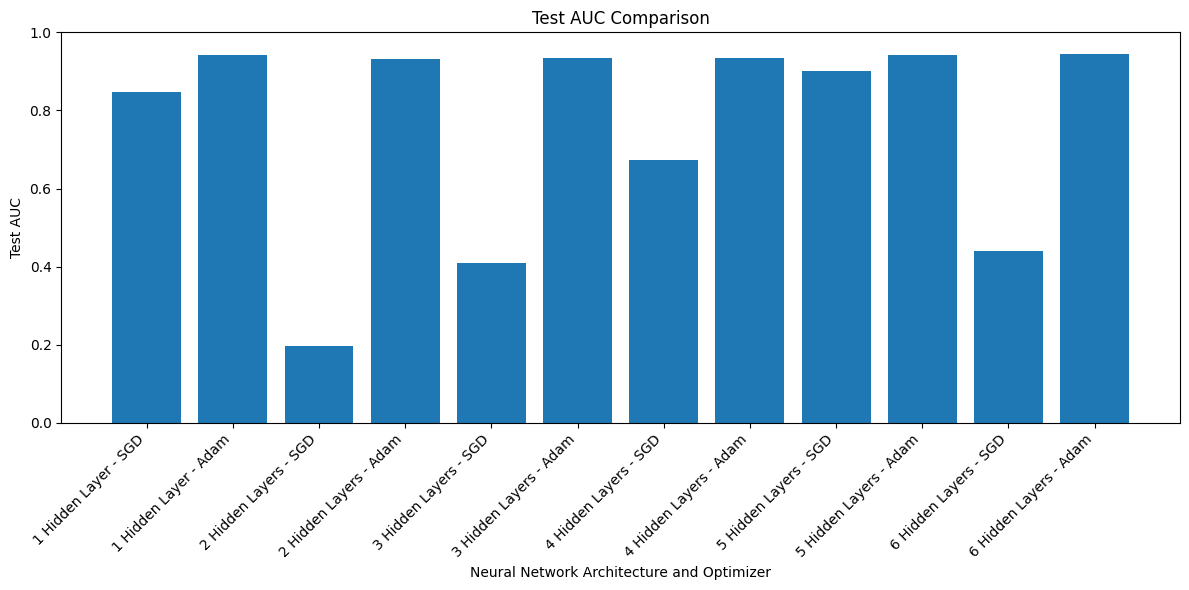

In [15]:
plt.figure(figsize=(12, 6))

labels = (
    results_df["Architecture"] +
    " - " +
    results_df["Optimizer"]
)

plt.bar(
    labels,
    results_df["Test AUC"]
)

plt.title("Test AUC Comparison")
plt.xlabel("Neural Network Architecture and Optimizer")
plt.ylabel("Test AUC")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

## Compare test accuracy

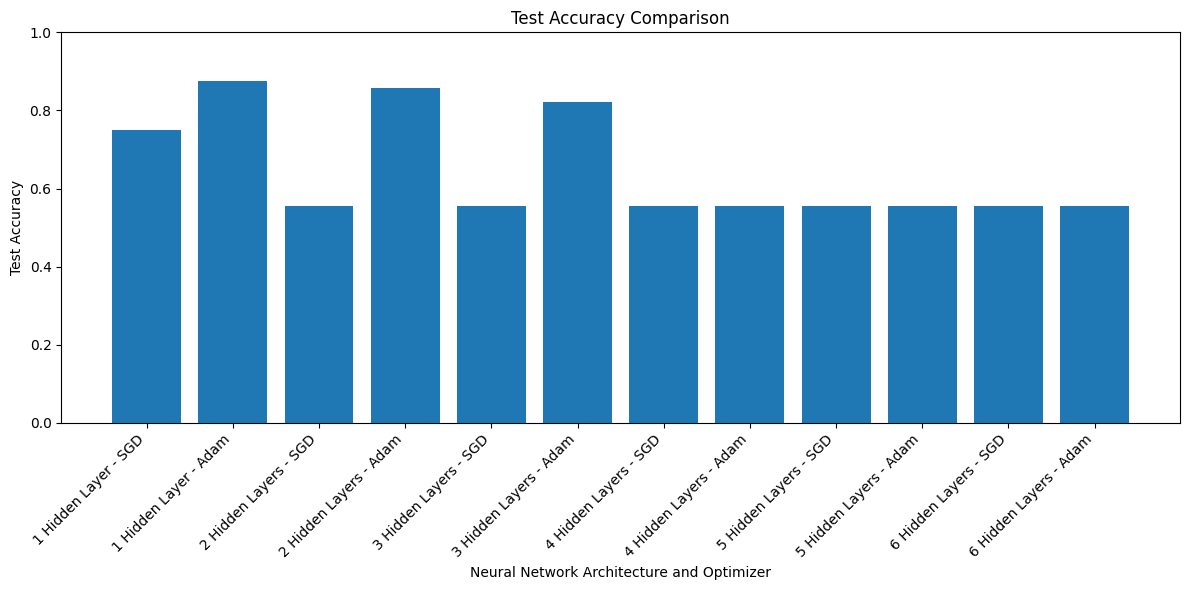

In [16]:
plt.figure(figsize=(12, 6))

plt.bar(
    labels,
    results_df["Test Accuracy"]
)

plt.title("Test Accuracy Comparison")
plt.xlabel("Neural Network Architecture and Optimizer")
plt.ylabel("Test Accuracy")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

## Compare test recall

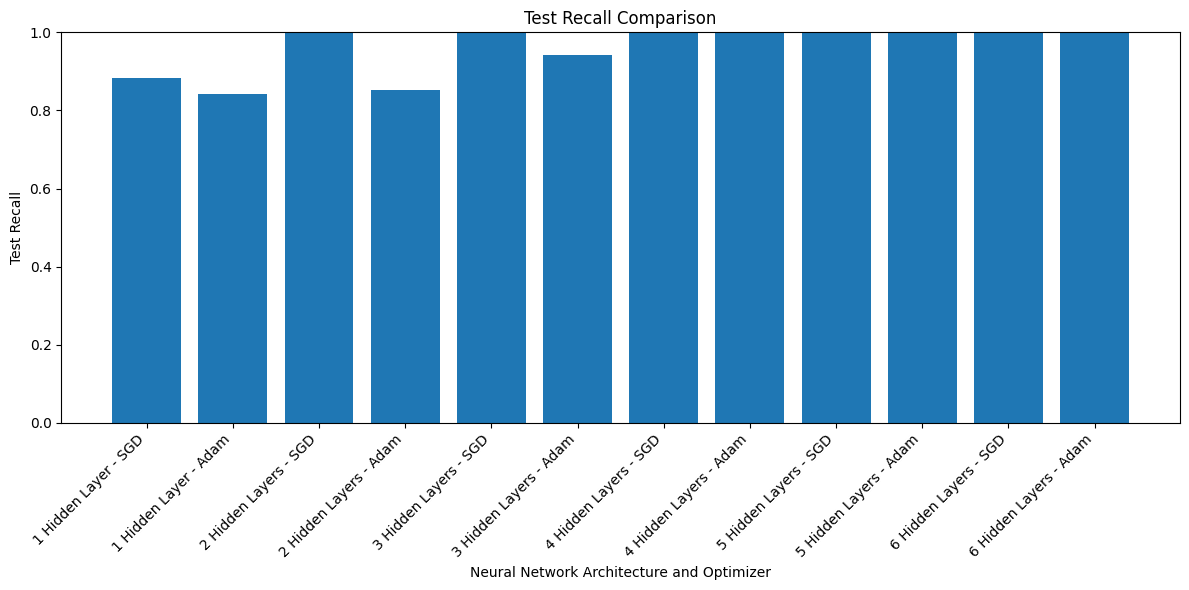

In [17]:
plt.figure(figsize=(12, 6))

plt.bar(
    labels,
    results_df["Test Recall"]
)

plt.title("Test Recall Comparison")
plt.xlabel("Neural Network Architecture and Optimizer")
plt.ylabel("Test Recall")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

## Compare training & validation loss

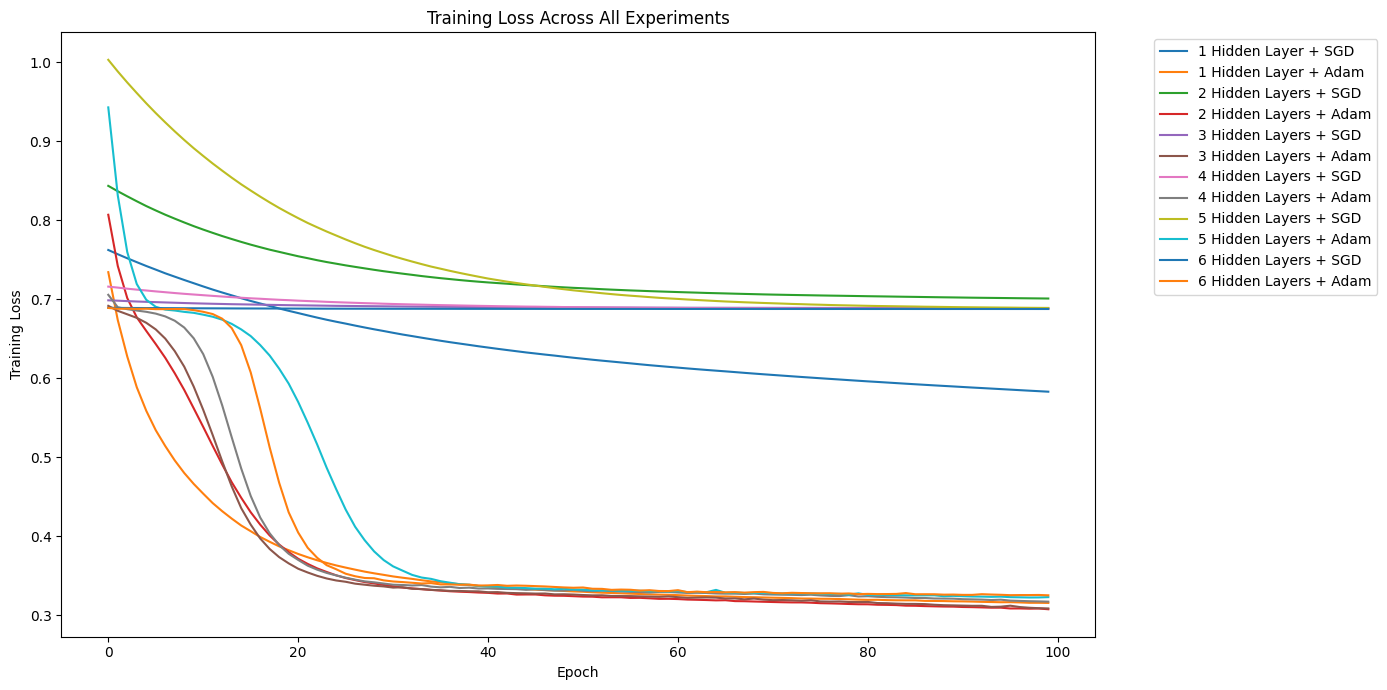

In [18]:
plt.figure(figsize=(14, 7))

for experiment_name, history in training_histories.items():

    plt.plot(
        history["train_loss"],
        label=experiment_name
    )

plt.title("Training Loss Across All Experiments")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

## Plot validation AUC across epochs

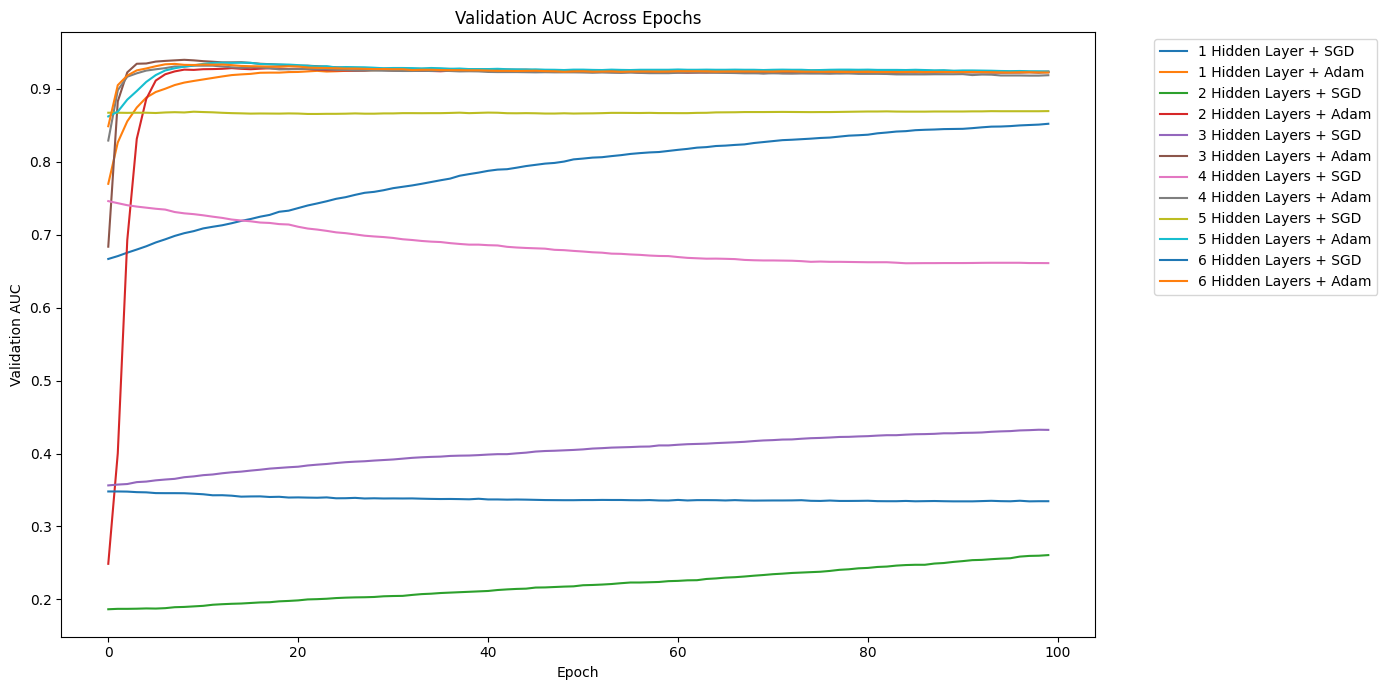

In [19]:
plt.figure(figsize=(14, 7))

for experiment_name, history in training_histories.items():

    plt.plot(
        history["val_auc"],
        label=experiment_name
    )

plt.title("Validation AUC Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Validation AUC")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

## Identifying the best model

In [20]:
best_model_row = results_df.loc[
    results_df["Validation AUC"].idxmax()
]

print("Best Model Based on Validation AUC")
print("-----------------------------------")

print("Architecture:", best_model_row["Architecture"])
print("Optimizer:", best_model_row["Optimizer"])
print("Best Epoch:", best_model_row["Best Epoch"])

print("\nFinal Test Performance:")

print("Test AUC:", round(best_model_row["Test AUC"], 4))
print("Test Accuracy:", round(best_model_row["Test Accuracy"], 4))
print("Test Recall:", round(best_model_row["Test Recall"], 4))

Best Model Based on Validation AUC
-----------------------------------
Architecture: 3 Hidden Layers
Optimizer: Adam
Best Epoch: 9

Final Test Performance:
Test AUC: 0.935
Test Accuracy: 0.8207
Test Recall: 0.9412


## Export experimental results

In [21]:
results_df.to_csv(
    "neural_network_experiment_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
